In [1]:
import osmnx as ox
import networkx as nx
import numpy as np
import os
import pickle
from tqdm import tqdm
import numpy as np
import pyswarms as ps
from pathos.multiprocessing import ProcessingPool as Pool
import osmnx as ox
import matplotlib.pyplot as plt

In [7]:
def base_statistics(G):
    print(f"{G.number_of_nodes()} nodi, {G.number_of_edges()} archi",
        "numero componenti connesse:", nx.number_connected_components(G.to_undirected()),
        "degree medio:", np.mean([d for n, d in G.degree()]) if G.number_of_nodes() > 0 else 0)

def check_active_network_visual(G_act, city_name="Città"):
    """
    Visualizza la rete active colorando di rosso le strade a scorrimento
    che potrebbero essere tangenziali finite per errore nella rete.
    """
    edge_colors = []
    edge_linewidths = []
    
    # Categorie stradali sospette per un pedone/bici se fuori contesto urbano
    suspect_highways = ['primary', 'primary_link', 'secondary', 'secondary_link']
    
    for u, v, key, data in G_act.edges(keys=True, data=True):
        highway = data.get('highway', '')
        
        # Gestione maxspeed (potrebbe essere una lista o una stringa)
        maxspeed = data.get('maxspeed', '50')
        if isinstance(maxspeed, list): maxspeed = maxspeed[0]
        try:
            speed_val = float(maxspeed)
        except ValueError:
            speed_val = 50.0
            
        # Condizione di allarme: strada principale O velocità alta
        if highway in suspect_highways or speed_val > 50:
            edge_colors.append('red')       # Rosso per le strade sospette
            edge_linewidths.append(1.5)
        else:
            edge_colors.append('#cccccc')   # Grigio chiaro per le strade sicure
            edge_linewidths.append(0.5)
            
    print(f"Generazione mappa diagnostica per {city_name}...")
    fig, ax = ox.plot_graph(
        G_act,
        node_size=0,
        edge_color=edge_colors,
        edge_linewidth=edge_linewidths,
        bgcolor='white',
        show=True,
        close=False
    )
    plt.show()

def get_largest_component(G):
    # Usiamo weakly_connected per i grafi diretti, per evitare che un senso unico 
    # digitato male isoli interi quartieri.
    largest_cc = max(nx.weakly_connected_components(G), key=len)
    return G.subgraph(largest_cc).copy()

def extract_value(data_attr, default_val, cast_type=float):
    """Funzione di supporto per estrarre valori puliti dai tag OSM (che a volte sono liste o stringhe vuote)"""
    if isinstance(data_attr, list):
        val = data_attr[0]
    else:
        val = data_attr
    try:
        return cast_type(val)
    except (ValueError, TypeError):
        return default_val

def get_safe_filename(city_name):
    """Sostituisce spazi e virgole per creare nomi file validi."""
    return city_name.replace(", ", "_").replace(" ", "_").replace(",", "_")

def simulate_true_multimodal_dynamics(
    city_name,
    M,
    N_users=10000,
    max_iter=10000,
    dt=0.01,
    rho=0.1,
    show_graphs=False,
    verbose=False,
):

    # 0. Setup Cartelle per il salvataggio
    os.makedirs("data/networks", exist_ok=True)
    os.makedirs("data/centralities", exist_ok=True)

    city_prefix = get_safe_filename(city_name)
    graph_path = f"data/networks/{city_prefix}_graph.pkl"
    centr_path = f"data/centralities/{city_prefix}_centr.pkl"

    # 1. Download o Caricamento dell'INTERA rete (auto, pedoni, bici)
    if os.path.exists(graph_path):
        if verbose:
            print(f"Caricamento rete locale trovata in: {graph_path}...")
        with open(graph_path, "rb") as f:
            G_full = pickle.load(f)
    else:
        if verbose:
            print(
                f"Scaricando la rete multimodale completa per: {city_name}..."
            )
        G_full = ox.graph_from_place(city_name, network_type="all")
        with open(graph_path, "wb") as f:
            pickle.dump(G_full, f)
        if verbose:
            print(f"Rete salvata con successo in: {graph_path}")

    # 2. Classificazione degli archi per modalità
    edges_car, edges_bus, edges_act = [], [], []

    for u, v, key, data in G_full.edges(keys=True, data=True):
        highway = data.get("highway", "")

        is_motorway = highway in [
            "motorway",
            "motorway_link",
            "trunk",
            "trunk_link",
        ]
        is_pedestrian_bike = highway in [
            "pedestrian",
            "path",
            "footway",
            "cycleway",
            "steps",
            "track",
        ]
        is_bus_only = highway in ["bus_guideway", "busway"]

        if not is_pedestrian_bike and not is_bus_only:
            edges_car.append((u, v, key))

        if not is_pedestrian_bike or is_bus_only:
            edges_bus.append((u, v, key))

        if not is_motorway and not is_bus_only:
            edges_act.append((u, v, key))

    # 3. Creazione dei Sottografi
    G_car_raw = G_full.edge_subgraph(edges_car)
    G_bus_raw = G_full.edge_subgraph(edges_bus)
    G_act_raw = G_full.edge_subgraph(edges_act)

    if verbose:
        print("Estrazione del Componente Principale (pulizia frammenti OSM)...")
    G_car = get_largest_component(G_car_raw)
    G_bus = get_largest_component(G_bus_raw)
    G_act = get_largest_component(G_act_raw)

    if show_graphs:
        print("\nStatistiche della rete Auto:")
        base_statistics(G_car)
        print("\nStatistiche della rete Bus:")
        base_statistics(G_bus)
        print("\nStatistiche della rete Active:")
        base_statistics(G_act)
        print()

        check_active_network_visual(G_act, city_name=city_name)

    # 4. Calcolo o Caricamento Centralità Indipendenti
    if os.path.exists(centr_path):
        if verbose:
            print(
                f"Caricamento centralità topologiche da file locale: {centr_path}..."
            )
        with open(centr_path, "rb") as f:
            centralities = pickle.load(f)
        centr_car = centralities["car"]
        centr_bus = centralities["bus"]
        centr_act = centralities["act"]
    else:
        centr_car = nx.edge_betweenness_centrality(G_car, weight="length", k=100)
        centr_bus = nx.edge_betweenness_centrality(G_bus, weight="length", k=100)
        centr_act = nx.edge_betweenness_centrality(G_act, weight="length", k=100)

        def normalize_dict(d):
            s = sum(d.values())
            return {k: v / s for k, v in d.items()} if s > 0 else d

        centr_car = normalize_dict(centr_car)
        centr_bus = normalize_dict(centr_bus)
        centr_act = normalize_dict(centr_act)

        with open(centr_path, "wb") as f:
            pickle.dump(
                {"car": centr_car, "bus": centr_bus, "act": centr_act}, f
            )

    # 5. Preparazione dei dati vettorizzati degli archi
    edges_data = []

    for u, v, key, data in G_full.edges(keys=True, data=True):
        L_e = data.get("length", 100.0)
        num_lanes = max(1, extract_value(data.get("lanes"), 1, int))
        v_car_kmh = extract_value(data.get("maxspeed"), 50.0, float)

        v_car = v_car_kmh * (1000 / 3600)
        v_bus = 20.0 * (1000 / 3600)
        v_act = 15.0 * (1000 / 3600)

        b = np.array([L_e / v_act, L_e / v_bus, L_e / v_car])

        edge_tuple = (u, v, key)
        pi_e = np.array([
            centr_act.get(edge_tuple, 0.0),  # Active
            centr_bus.get(edge_tuple, 0.0),  # Bus
            centr_car.get(edge_tuple, 0.0),  # Car
        ])

        if np.sum(pi_e) > 0:
            edges_data.append(
                {"L_e_lanes": num_lanes, "pi_e": pi_e, "b": b}
            )

    # 6. Simulazione Dinamica (Replicator Dynamics)
    Pi = np.array([ed["pi_e"] for ed in edges_data])  # (N_archi, 3)
    B = np.array([ed["b"] for ed in edges_data])  # (N_archi, 3)
    L = np.array([[ed["L_e_lanes"]] for ed in edges_data])  # (N_archi, 1)

    x = np.array([0.33, 0.33, 0.34])  # [Active, Bus, Car]
    tolerance = 1e-6

    x_history = [x.copy()]

    # disable=not verbose disabilita graficamente la progress bar durante la PSO
    for iteration in tqdm(
        range(max_iter),
        desc="Simulazione in corso",
        disable=not verbose,
        leave=False,
    ):

        # 1. Densità D
        D = (N_users * (Pi * x)) / L

        # 2. Costo C_all
        C_all = B + D.dot(M.T)

        # 3. Costo medio per modalità
        C = np.sum(Pi * C_all, axis=0)

        # Replicator Dynamics
        mu = np.dot(x, C)
        dx = rho * x * (mu - C)

        x_new = x + dt * dx
        x_new = np.clip(x_new, 0.001, 0.999)
        x_new = x_new / np.sum(x_new)

        x_history.append(x_new.copy())

        if np.linalg.norm(x_new - x) < tolerance:
            if verbose:
                tqdm.write(
                    f"\nEquilibrio stabile raggiunto all'iterazione {iteration}."
                )
            x = x_new
            break

        x = x_new

    if verbose:
        print("Simulazione completata.\n")

    risultato = {
        "Active": round(x[0] * 100, 2),
        "Bus": round(x[1] * 100, 2),
        "Car": round(x[2] * 100, 2),
    }

    if verbose:
        print("--- QUOTE MODALI FINALI (EQUILIBRIO) ---")
        for mezzo, quota in risultato.items():
            print(f"{mezzo}: {quota}%")

    return {"history": np.array(x_history)}


Statistiche della rete Auto:
4352 nodi, 9247 archi numero componenti connesse: 1 degree medio: 4.249540441176471

Statistiche della rete Bus:
4352 nodi, 9247 archi numero componenti connesse: 1 degree medio: 4.249540441176471

Statistiche della rete Active:
5122 nodi, 12508 archi numero componenti connesse: 1 degree medio: 4.884029675907849

Generazione mappa diagnostica per Pordenone, Italy...


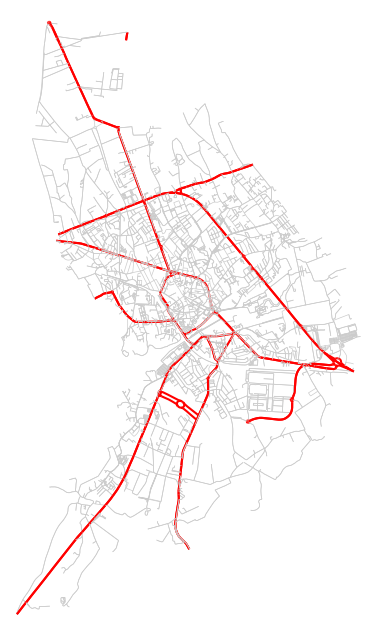

In [8]:
# Matrice di Interazione M (3x3) -> [Active, Bus, Car]
# Righe: chi subisce il ritardo. Colonne: chi causa il ritardo.
M_fixed = np.array([
    [0.05, 0.01, 0.01],  # Active 
    [0.05, 0.25, 0.20],  # Bus 
    [0.10, 0.30, 0.50]   # Car 
])

cities = ["Pordenone, Italy", "Breclav, Czechia", "Regensburg, Germany"]
populations = [53000, 25000, 150000]  # Popolazioni fittizie per le città

test_index = 0
# Test su una città medio-piccola
citta_test = cities[test_index]
user_test = populations[test_index]

risultato = simulate_true_multimodal_dynamics(
    city_name=citta_test, 
    M=M_fixed, 
    N_users=user_test, 
    rho=0.05,
    show_graphs=True,
    verbose=False
)

In [7]:
def plot_history(history, city_name):
    import matplotlib.pyplot as plt
    
    plt.figure(figsize=(10, 6))
    plt.plot(history[:, 0], label='Active', color='green')
    plt.plot(history[:, 1], label='Bus', color='blue')
    plt.plot(history[:, 2], label='Car', color='red')
    
    plt.title(f"Dynamic Evolution of Modal Shares in {city_name}")
    plt.xlabel("Iterations")
    plt.ylabel("Modal Share")
    plt.legend()
    plt.grid(True)
    plt.ylim(0, 1)
    plt.show()

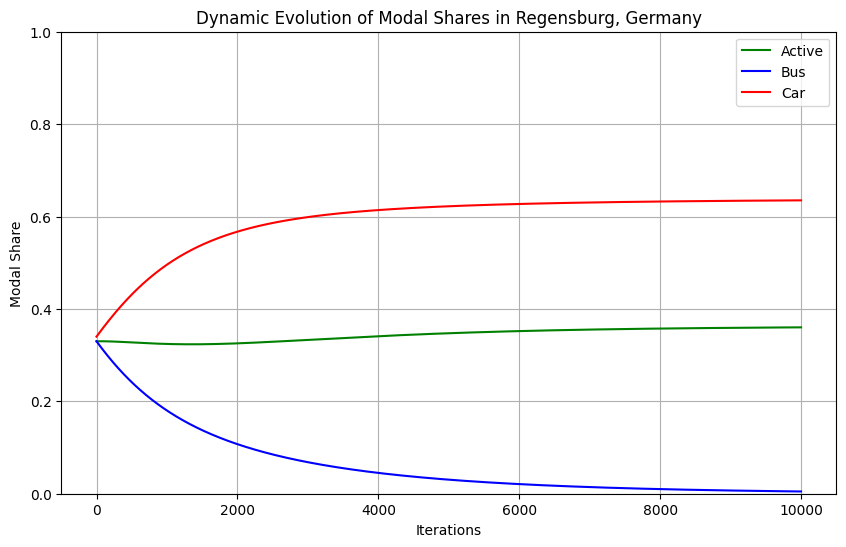

In [8]:
plot_history(risultato['history'], citta_test)

In [ ]:
# ==========================================
# 1. SETUP DATI E PARAMETRI
# ==========================================
# Ipotizziamo 3 modalità (es. Auto, Trasporto Pubblico, Bici/Piedi) -> Matrice 3x3
n_modes = 3
n_params = n_modes * n_modes

# Dati fittizi per l'esempio
cities = ["Pordenone, Italy", "Breclav, Czechia", "Regensburg, Germany"]
populations = [53000, 25000, 150000]  # Popolazioni fittizie per le città
real_shares = [np.array([0.16, 0.06, 0.78]),  # Pordenone
               np.array([0.61, 0.24, 0.15]),  # Breclav
               np.array([0.48, 0.11, 0.41])]  # Regensburg

# check probailita sommano a uno
if not all(np.isclose(np.sum(shares), 1.0) for shares in real_shares):
    raise ValueError("Le quote modali reali devono sommare a 1 per ogni città.")

# ==========================================
# 2. FUNZIONE DEL MODELLO TEORICO
# ==========================================
def simulate_city_shares(M, city_name, population):
    """
    QUI INSERISCI IL TUO MODELLO DI RETE.
    Deve prendere la matrice M, la rete della città e restituire le quote modali stimate.
    """
    result = simulate_true_multimodal_dynamics(city_name, M, N_users=population, rho=0.1, show_graphs=False)
    final_shares = result['history'][-1]  # Prendiamo l'ultimo stato della simulazione
    return final_shares    

# ==========================================
# 3. FUNZIONE DI COSTO (Loss Function)
# ==========================================
def evaluate_particle(particle):
    """
    Valuta una singola particella (che rappresenta una singola matrice M).
    """
    # Ricostruiamo la matrice (es. 3x3) dal vettore 1D della particella
    M = particle.reshape((n_modes, n_modes))
    
    # PENALITA' VINCOLO: Gli elementi sulla diagonale devono essere i massimi della riga
    penalty = 0.0
    for i in range(n_modes):
        row_max = np.max(M[i, :])
        if M[i, i] < row_max:
            # Aggiungiamo una penalità severa proporzionale alla violazione
            penalty += (row_max - M[i, i]) * 10000 
            
    # Calcolo dell'errore (Loss) su tutte le città
    total_loss = 0.0
    for idx, city in enumerate(cities):
        pred_shares = simulate_city_shares(M, city, populations[idx])
        
        # Mean Squared Error (MSE) tra quote previste e reali
        mse = np.sum((pred_shares - real_shares[idx])**2)
        total_loss += mse
        
    return total_loss + penalty

def cost_function(particles):
    global current_iteration
    current_iteration += 1

    n_particles = particles.shape[0]
    
    # Pathos gestisce molto meglio le funzioni nello stesso file
    with Pool(nodes=4) as pool: 
        costs = pool.map(evaluate_particle, [particles[p] for p in range(n_particles)])

    # print(f"Iterazione {current_iteration}")

    return np.array(costs)

In [10]:
# ==========================================
# 4. CONFIGURAZIONE E LANCIO PSO
# ==========================================
current_iteration = 0

if __name__ == "__main__":
    # Parametri iper-euristici della PSO: 
    # c1 (cognitivo), c2 (sociale), w (inerzia)
    options = {'c1': 1.5, 'c2': 1.5, 'w': 0.7}

    # Limiti di ricerca per i parametri (costi marginali plausibili)
    # Impostiamo valori minimi (es. 0) e massimi (es. 10) per i 9 elementi
    min_bounds = np.zeros(n_params)
    max_bounds = np.ones(n_params) * 10.0
    bounds = (min_bounds, max_bounds)

    # Inizializzazione dello swarm
    optimizer = ps.single.GlobalBestPSO(n_particles=30, 
                                        dimensions=n_params, 
                                        options=options, 
                                        bounds=bounds)

    # Lancio dell'ottimizzazione (es. 100 iterazioni)
    best_cost, best_M_flat = optimizer.optimize(cost_function, iters=100)

    # Risultato
    best_M = best_M_flat.reshape((n_modes, n_modes))
    print("\nOttimizzazione completata!")
    print("Miglior Costo:", best_cost)
    print("Matrice M Globale Ottima:\n", best_M)

2026-08-19 15:48:50,673 - pyswarms.single.global_best - INFO - Optimize for 100 iters with {'c1': 1.5, 'c2': 1.5, 'w': 0.7}
pyswarms.single.global_best:   1%|          |1/100, best_cost=0.625

Iterazione 1


pyswarms.single.global_best:   2%|▏         |2/100, best_cost=0.35 

Iterazione 2


pyswarms.single.global_best:   3%|▎         |3/100, best_cost=0.35

Iterazione 3


... (190 outputs left out)

pyswarms.single.global_best:  99%|█████████▉|99/100, best_cost=0.277

Iterazione 99


pyswarms.single.global_best: 100%|██████████|100/100, best_cost=0.277
2026-08-19 17:41:58,684 - pyswarms.single.global_best - INFO - Optimization finished | best cost: 0.2770095311740105, best pos: [8.20144298 8.11132199 4.89491649 5.05241861 6.88198082 5.0081357
 3.19717004 0.72405412 7.50248228]


Iterazione 100

Ottimizzazione completata!
Miglior Costo: 0.2770095311740105
Matrice M Globale Ottima:
 [[8.20144298 8.11132199 4.89491649]
 [5.05241861 6.88198082 5.0081357 ]
 [3.19717004 0.72405412 7.50248228]]


In [12]:
import pandas as pd

# 1. Stampa della Matrice M stimata
print("\n" + "=" * 40)
print("MATRICE M PREDETTA")
print("=" * 40)
print(best_M)

# 2. Calcolo delle quote predette per tutte le città
results = []

print("\nCalcolo delle quote modali predette per le città...")
for idx, city in enumerate(cities):

    # Esegue la simulazione con la matrice 'best_M'
    sim_out = simulate_true_multimodal_dynamics(
        city_name=city,
        M=best_M,
        N_users=populations[idx],
        verbose=False,
        show_graphs=False,
    )

    # Estrae l'ultimo stato di equilibrio della dinamica (convertito in %)
    pred_share = sim_out["history"][-1] * 100

    results.append({
        "Città": city,
        "Act Reale (%)": round(real_shares[idx][0] * 100, 1),
        "Act Pred (%)": round(pred_share[0], 1),
        "Bus Reale (%)": round(real_shares[idx][1] * 100, 1),
        "Bus Pred (%)": round(pred_share[1], 1),
        "Car Reale (%)": round(real_shares[idx][2] * 100, 1),
        "Car Pred (%)": round(pred_share[2], 1),
    })

# 3. Visualizzazione in formato tabella
df_results = pd.DataFrame(results)
print("\n" + "=" * 60)
print("CONFRONTO QUOTE MODALI: REALI vs PREDETTE")
print("=" * 60)
print(df_results.to_string(index=False))


MATRICE M PREDETTA
[[8.20144298 8.11132199 4.89491649]
 [5.05241861 6.88198082 5.0081357 ]
 [3.19717004 0.72405412 7.50248228]]

Calcolo delle quote modali predette per le città...

CONFRONTO QUOTE MODALI: REALI vs PREDETTE
              Città  Act Reale (%)  Act Pred (%)  Bus Reale (%)  Bus Pred (%)  Car Reale (%)  Car Pred (%)
   Pordenone, Italy           16.0          37.0            6.0          13.9           78.0          49.1
   Breclav, Czechia           61.0          44.4           24.0          11.0           15.0          44.6
Regensburg, Germany           48.0          39.6           11.0          13.9           41.0          46.5


In [ ]:
M_fixed = np.array([
    [0.05, 0.01, 0.01],  # Active 
    [0.05, 0.25, 0.20],  # Bus 
    [0.10, 0.30, 0.50]   # Car 
])

# Test su una città medio-piccola
citta_test = "Pordenone, Italy"

for N_users in [50000]:#, 20000, 30000, 40000, 50000, 60000, 70000, 80000, 90000, 100000]:
    print(f"\n--- Simulazione per {N_users} utenti ---")
    risultato = simulate_true_multimodal_dynamics(
        city_name=citta_test, 
        M=M_fixed, 
        N_users=N_users, 
        rho=0.1,
        show_graphs=False
    )